# Netflix Content Evolution Analysis
## Data Inspection and Cleaning

### Project Objective
The objective of this project is to analyze how Netflix's
content library has evolved over time.

### Dataset
Netflix Movies and TV Shows Dataset

- Records: 8,807
- Features: 12
- Content types: Movies and TV Shows

### Data Preparation
This notebook covers:
1. Dataset loading and inspection
2. Data quality assessment
3. Missing value analysis
4. Duplicate detection
5. Data cleaning and preprocessing
6. Exporting the cleaned dataset

### Import Libraries


In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configure pandas display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


### Load the dataset

In [3]:


# Load the CSV file
df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


### Inspect the dataset

In [4]:

# Check the first five records
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Dataset shape: (8807, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB



##  Missing Value Analysis

Missing values are common in real-world datasets. Before performing data cleaning, we need to identify which columns contain missing information and understand how much data is affected.

We will examine both the number and percentage of missing values in each column. This will help us decide how to handle missing information without unnecessarily removing useful records.


In [5]:

# Calculate missing values in each column
missing_values = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing_values / len(df)) * 100

# Combine results into a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage.round(2)
})

# Display columns containing missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Values', ascending=False)

display(missing_summary)


,Missing Values,Percentage (%)
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


### visualize missing values

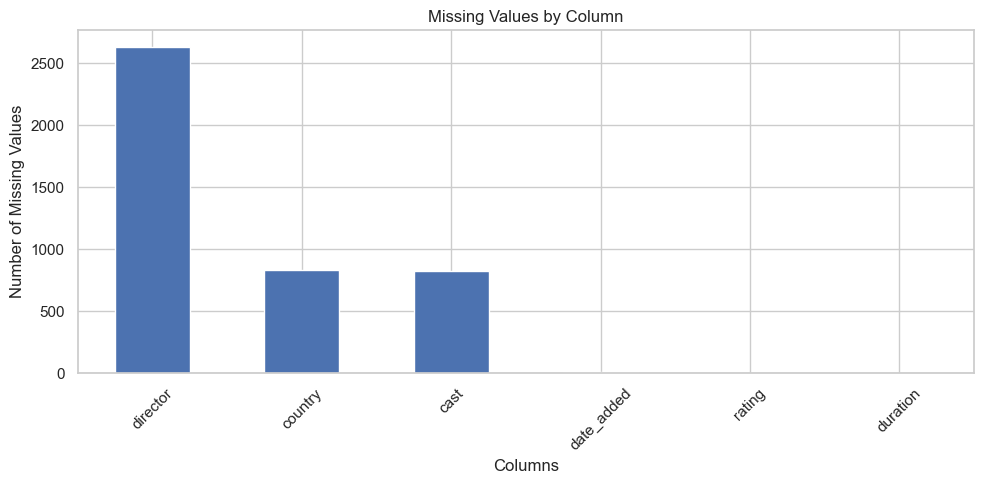

In [6]:

# Visualize missing values
plt.figure(figsize=(10, 5))

missing_summary['Missing Values'].plot(
    kind='bar',
    title='Missing Values by Column'
)

plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## Duplicate Record Analysis

Duplicate records can affect the accuracy of data analysis, especially when counting titles or calculating distributions.

We will check for completely duplicated rows and duplicated show IDs. Since each show ID should identify a unique Netflix title, repeated IDs need to be investigated.


In [7]:

# Check completely duplicated rows
duplicate_rows = df.duplicated().sum()

# Check duplicated show IDs
duplicate_ids = df['show_id'].duplicated().sum()

print("Completely duplicated rows:", duplicate_rows)
print("Duplicated show IDs:", duplicate_ids)


Completely duplicated rows: 0
Duplicated show IDs: 0


### Check categorical value

In [8]:

# Check unique content types
print("Content types:")
print(df['type'].value_counts())

# Check unique ratings
print("\nContent ratings:")
print(df['rating'].value_counts())

# Check release year range
print("\nRelease year range:")
print(df['release_year'].min(), "-", df['release_year'].max())


Content types:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Content ratings:
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

Release year range:
1925 - 2021


### Investigate inconsistent ratings


##  Data Consistency Analysis

During the inspection of categorical values, we identified unusual entries in the rating column.

The values "74 min", "84 min" and "66 min" do not represent content ratings. They appear to represent movie durations.

We will investigate the affected records and check whether their duration values are missing before deciding how to correct them.


In [9]:

# Identify unusual values in the rating column

unusual_ratings = ['74 min', '84 min', '66 min']

# Display records containing these values
rating_issues = df[df['rating'].isin(unusual_ratings)]

display(rating_issues[
    ['show_id', 'title', 'type', 'rating', 'duration']
])


,show_id,title,type,rating,duration
5541,s5542,Louis C.K. 2017,Movie,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN



### Initial Data Quality Findings

The initial inspection identified several data quality issues:

1. The director column contains the highest number of missing values, followed by country and cast.
2. A small number of records have missing dates, ratings and durations.
3. No completely duplicated records or duplicate show IDs were found.
4. Movies account for a larger proportion of the dataset than TV Shows.
5. Some unusual values were identified in the rating column, suggesting possible inconsistencies between rating and duration information.

These findings will guide the next stage of data cleaning and preprocessing.



##  Correcting Inconsistent Rating and Duration Values

During data inspection, three records were found with movie durations incorrectly stored in the rating column.

After examining these records, we confirmed that:
- All three records are Movies.
- Their rating values contain durations in minutes.
- Their duration fields are missing.

We will transfer these values into the duration column and mark their ratings as Unknown. This preserves the available information without inventing ratings.


In [10]:

# Identify duration values incorrectly stored in rating

incorrect_duration_mask = (
    df['rating'].str.contains(r'^\d+\s*min$', na=False)
    & df['duration'].isna()
)

# Display affected records before correction
display(df.loc[
    incorrect_duration_mask,
    ['title', 'type', 'rating', 'duration']
])

# Move the misplaced values into the duration column
df.loc[incorrect_duration_mask, 'duration'] = (
    df.loc[incorrect_duration_mask, 'rating']
)

# Mark the missing ratings for these records
df.loc[incorrect_duration_mask, 'rating'] = np.nan

print("Records corrected:", incorrect_duration_mask.sum())


,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


Records corrected: 3


In [11]:

# Check the corrected records

display(df.loc[
    df['title'].str.contains('Louis C.K.', case=False, na=False),
    ['title', 'type', 'rating', 'duration']
])


,title,type,rating,duration
5541,Louis C.K. 2017,Movie,NaN,74 min
5794,Louis C.K.: Hilarious,Movie,NaN,84 min
5813,Louis C.K.: Live at the Comedy Store,Movie,NaN,66 min



## 9. Handling Missing Values

After correcting the misplaced duration values, we will handle the remaining missing information.

Our approach is to preserve records wherever possible:

- Director: Replace missing values with "Unknown".
- Cast: Replace missing values with "Unknown".
- Country: Replace missing values with "Unknown".
- Rating: Replace missing values with "Unknown".
- Duration: Replace missing values with "Unknown".
- Date added: Keep missing values as NaT because the actual dates cannot be determined from the dataset.

We will not delete records simply because descriptive information is unavailable.


In [13]:

# Handle missing descriptive information

columns_to_fill = [
    'director',
    'cast',
    'country',
    'rating',
    'duration'
]

for column in columns_to_fill:
    df[column] = df[column].fillna('Unknown')

print("Missing descriptive values handled.")


Missing descriptive values handled.


In [14]:

# Check remaining missing values

print("Missing values after cleaning:")
display(df.isnull().sum())


Missing values after cleaning:


show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

### Convert date_added into datetime


## 10. Date Conversion and Feature Engineering

The date_added column represents when a title was added to Netflix. Initially, this column is stored as text.

We will convert it into a datetime format so that we can extract the year and analyze yearly content additions.

We will also create a new column called year_added, which will be useful for the next stage of exploratory data analysis.


In [15]:

# Remove unnecessary spaces from date values
df['date_added'] = df['date_added'].str.strip()

# Convert date_added into datetime format
df['date_added'] = pd.to_datetime(
    df['date_added'],
    format='%B %d, %Y',
    errors='coerce'
)

# Extract the year when each title was added
df['year_added'] = df['date_added'].dt.year

# Use nullable integer format to preserve missing dates
df['year_added'] = df['year_added'].astype('Int64')

print("Date conversion completed!")

display(df[['title', 'date_added', 'year_added']].head(10))


Date conversion completed!


,title,date_added,year_added
0,Dick Johnson Is Dead,2021-09-25,2021
1,Blood & Water,2021-09-24,2021
2,Ganglands,2021-09-24,2021
3,Jailbirds New Orleans,2021-09-24,2021
4,Kota Factory,2021-09-24,2021
5,Midnight Mass,2021-09-24,2021
6,My Little Pony: A New Generation,2021-09-24,2021
7,Sankofa,2021-09-24,2021
8,The Great British Baking Show,2021-09-24,2021
9,The Starling,2021-09-24,2021



## 11. Text Standardization

Some text fields contain comma-separated values, such as country, cast, director and genres.

We will standardize these values by removing unnecessary spaces around the text and comma-separated items.

This will make future filtering, grouping and analysis more consistent.


In [16]:

# Identify text columns
text_columns = [
    'show_id', 'type', 'title', 'director',
    'cast', 'country', 'rating', 'duration',
    'listed_in', 'description'
]

# Remove leading and trailing spaces
for column in text_columns:
    df[column] = df[column].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Standardize comma-separated values
def clean_separated_values(value):
    if pd.isna(value):
        return value

    values = [item.strip() for item in value.split(',')]

    return ', '.join(values)

for column in ['director', 'cast', 'country', 'listed_in']:
    df[column] = df[column].apply(clean_separated_values)

print("Text standardization completed.")


Text standardization completed.



## 13. Investigating Missing Date Values

The date_added column contains 10 missing values.

Since the actual dates are not available in the original dataset, we cannot reliably determine when these titles were added to Netflix.

We will inspect the affected records and retain them without assigning estimated dates. These records can still be used for other analyses that do not depend on the date_added field.


In [19]:

# Identify records with missing addition dates

missing_date_records = df[df['date_added'].isna()]

print("Number of records with missing dates:",
      len(missing_date_records))

display(missing_date_records[
    ['show_id', 'title', 'type', 'release_year',
     'country', 'date_added', 'year_added']
])


Number of records with missing dates: 10


,show_id,title,type,release_year,country,date_added,year_added
6066,s6067,A Young Doctor's Notebook and Other Stories,TV Show,2013,United Kingdom,NaT,<NA>
6174,s6175,Anthony Bourdain: Parts Unknown,TV Show,2018,United States,NaT,<NA>
6795,s6796,Frasier,TV Show,2003,United States,NaT,<NA>
6806,s6807,Friends,TV Show,2003,United States,NaT,<NA>
6901,s6902,Gunslinger Girl,TV Show,2008,Japan,NaT,<NA>
7196,s7197,Kikoriki,TV Show,2010,Unknown,NaT,<NA>
7254,s7255,La Familia P. Luche,TV Show,2012,United States,NaT,<NA>
7406,s7407,Maron,TV Show,2016,United States,NaT,<NA>
7847,s7848,Red vs. Blue,TV Show,2015,United States,NaT,<NA>
8182,s8183,The Adventures of Figaro Pho,TV Show,2015,Australia,NaT,<NA>



## 14. Date Validation

After converting date_added into datetime format and creating year_added, we will verify that the date conversion was successful.

We will check the date range, data types, missing values and consistency between date_added and year_added.


In [20]:

# Check date range
print("Earliest addition date:", df['date_added'].min())
print("Latest addition date:", df['date_added'].max())

# Check data types
print("\nDate column type:", df['date_added'].dtype)
print("Year added type:", df['year_added'].dtype)

# Verify year extraction
valid_dates = df['date_added'].notna()

year_check = (
    df.loc[valid_dates, 'date_added'].dt.year
    == df.loc[valid_dates, 'year_added']
).all()

print("\nYear extraction correct:", year_check)

# Check missing dates
print("Missing date_added:", df['date_added'].isna().sum())
print("Missing year_added:", df['year_added'].isna().sum())


Earliest addition date: 2008-01-01 00:00:00
Latest addition date: 2021-09-25 00:00:00

Date column type: datetime64[ns]
Year added type: Int64

Year extraction correct: True
Missing date_added: 10
Missing year_added: 10


In [21]:

print("Earliest release year:", df['release_year'].min())
print("Latest release year:", df['release_year'].max())

print("Missing release years:",
      df['release_year'].isna().sum())


Earliest release year: 1925
Latest release year: 2021
Missing release years: 0



## 12. Final Data Validation

After completing the cleaning process, we need to verify the dataset.

We will check:
- Dataset dimensions.
- Remaining missing values.
- Duplicate records.
- Data types.
- Content type consistency.

This ensures that the dataset is ready for the next stage of analysis.


In [22]:

# Final dataset validation

print("FINAL DATASET VALIDATION")
print("-" * 40)

print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df['show_id'].duplicated().sum())

print("\nRemaining missing values:")
display(df.isnull().sum())

# Confirm expected conditions
assert len(df) == 8807
assert df['show_id'].is_unique
assert df['date_added'].isna().sum() == 10
assert df['year_added'].isna().sum() == 10
assert df['date_added'].dtype == 'datetime64[ns]'
assert year_check

print("\nAll validation checks passed!")


FINAL DATASET VALIDATION
----------------------------------------
Dataset shape: (8807, 13)

Duplicate rows: 0
Duplicate IDs: 0

Remaining missing values:


show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
year_added      10
dtype: int64


All validation checks passed!


In [23]:
from pathlib import Path

# Identify the project directory
current_directory = Path.cwd()

if current_directory.name == 'notebooks':
    project_directory = current_directory.parent
else:
    project_directory = current_directory

# Create the data directory if it does not exist
output_directory = project_directory / 'data'
output_directory.mkdir(exist_ok=True)

# Export the cleaned dataset
output_path = output_directory / 'netflix_titles_cleaned.csv'

df.to_csv(output_path, index=False)

print("Cleaned dataset exported successfully!")
print("Location:", output_path)
print("Records:", len(df))
print("Columns:", len(df.columns))

Cleaned dataset exported successfully!
Location: c:\Users\Acer\OneDrive\Desktop\Netflix\data\netflix_titles_cleaned.csv
Records: 8807
Columns: 13
